# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'   # [정답안] 예시 번호
if not student_id or not student_id.isascii() or not student_id.isdigit():
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')
print('수험번호:', student_id)

수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 2-1. (예측)

> **[예측 문제]** 공식 샘플의 형식·제약을 그대로 따르고 데이터와 함정만 바꾼 연습 문제입니다. 실제 시험 문제가 아닙니다.

신상품 카테고리가 늘면서 **카테고리별 학습 사진 수가 크게 차이 나는(긴 꼬리, 최대 800장 ~ 최소 30장)** 데이터로 모델을 학습해야 합니다. 검증 데이터는 클래스마다 100장씩 균형입니다.

Task A, Task B, Task C로 이루어져 있으며, 수정해야 하는 셀에는 표시가 되어 있습니다. 그 외 셀은 수정하지 마세요.

- Task A는 `FashionModel`에서 학습 범위를 설정합니다. **고정: `patch_embed`, `stages[0]`, `stages[1]`, `stages[2]` / 학습: `stages[3]`, `head` 전체**
- Task B는 `custom_loss(logits, targets)`에 **클래스 불균형을 고려한 Loss**를 직접 구현합니다. (예: Focal Loss, 클래스 가중 CE, Logit Adjustment, Label Smoothing과의 조합)
- Task C는 `batch_size`, `learning_rate`, `epochs`를 조정합니다.
- 모델은 TinyViT 5M `dist_in22k_ft_in1k`, 입력 높이 80 × 너비 60 유지. 데이터 분할·전처리·구성 블록·가중치 로딩·학습/평가 코드는 수정 금지.

### 주의! 노트북에 반드시 포함
- 고정/학습 구간과 수정한 코드
- 선택한 Loss와 구현 코드, 선택 이유(주석)
- 비교한 하이퍼파라미터와 validation 결과, 최종 설정
- epoch별 validation macro-F1과 best validation macro-F1

> ## [예측 문제 정답안]
> Task A stages[3]+head 학습 / Task B 클래스 가중 Focal Loss / Task C 학습률·batch 조정

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

아래 셀은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀 있는지를 체크합니다.
꼭 실행해서 확인 후에 진행하세요. 오류가 발생하면 이 폴더의 README.md를 참고해 환경을 다시 확인하세요.
특히 VS Code, PyCharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# [정답안] 환경 확인 - CPU/GPU 겸용 (문제 노트북은 GPU가 없으면 여기서 멈춥니다)
import sys
from pathlib import Path

print('Python:', sys.version.split()[0])
print('현재 커널:', sys.executable)
print('작업 폴더:', Path.cwd())
expected_env = Path.cwd() / '.venv'
if Path(sys.prefix).resolve() != expected_env.resolve():
    raise RuntimeError(f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요.")
import torch, torchvision, timm
print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)
if torch.cuda.is_available():
    DEVICE, QUICK = 'cuda', False
    print('GPU:', torch.cuda.get_device_name(0), '-> 원본 설정 그대로 실행합니다.')
else:
    DEVICE, QUICK = 'cpu', True
    print('GPU 없음 -> QUICK 모드: 학습 데이터와 epoch를 줄여 CPU에서 끝까지 실행합니다 (점수는 낮게 나옴).')

Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_final_predict


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
GPU: NVIDIA GeForce RTX 5060 Ti -> 원본 설정 그대로 실행합니다.


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 데이터 준비

환경과 데이터는 이미 준비되어 있습니다. VS Code 또는 PyCharm에서 이 폴더를 여세요. 노트북 커널/인터프리터는 이 폴더의 `.venv\Scripts\python.exe`를 선택합니다. 데이터는 같은 폴더의 `data/`에서 읽습니다. 이미지는 RGB, 가로 60 × 세로 80이며 리사이즈하지 않습니다. 이 노트북에서는 데이터를 다운로드하거나 다시 분할하지 않습니다. validation 데이터는 변경하지 마세요.
또한 DataLoader과 Transform 역시 수정하면 안 됩니다.

P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다.


In [3]:
# 수정 금지

from pathlib import Path
import random
import json
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import f1_score

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')


사용 장치: NVIDIA GeForce RTX 5060 Ti


In [4]:
# 수정 금지

data_path = Path('data/f2_1_longtail/prepared.npz')
if not data_path.is_file() or not data_path.with_name('classes.json').is_file():
    raise FileNotFoundError('데이터가 없습니다. 먼저 setup.cmd를 실행하고, 작업 폴더를 이 노트북이 있는 폴더로 맞추세요.')

In [5]:
# 수정 금지

with data_path.with_name('classes.json').open(encoding='utf-8') as file:
    class_names = json.load(file)
num_classes = len(class_names)

with np.load(data_path, allow_pickle=False) as data:
    train_images = data['train_images']
    train_labels = data['train_labels'].reshape(-1)
    val_images = data['val_images']
    val_labels = data['val_labels'].reshape(-1)

print('클래스:', num_classes)
print('학습:', len(train_images), '검증:', len(val_images))
print('이미지 크기:', train_images[0].shape)


클래스: 20
학습: 4844 검증: 2000
이미지 크기: (80, 60, 3)


> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [6]:
# [정답안 전용] CPU QUICK 모드에서만 데이터를 줄입니다.
if QUICK:
    _rng = np.random.default_rng(0)
    _keep = np.sort(_rng.choice(len(train_labels), size=min(3000, len(train_labels)), replace=False))
    train_images, train_labels = train_images[_keep], train_labels[_keep]
    _keep = np.sort(_rng.choice(len(val_labels), size=min(800, len(val_labels)), replace=False))
    val_images, val_labels = val_images[_keep], val_labels[_keep]
    print('QUICK 모드 데이터:', len(train_labels), len(val_labels))

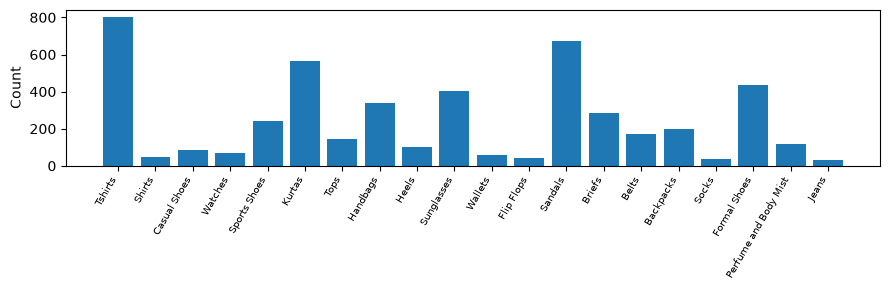

In [7]:
# 수정 금지
# Task B에서 사용할 수 있는 클래스별 학습 이미지 수입니다.

class_counts = torch.bincount(torch.as_tensor(train_labels), minlength=num_classes).float()
plt.figure(figsize=(9, 3))
plt.bar(range(num_classes), class_counts.numpy())
plt.xticks(range(num_classes), class_names, rotation=60, ha='right', fontsize=7)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [8]:
# 수정 금지

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [9]:
# 수정 금지

class FashionDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.transform(self.images[index]), int(self.labels[index])


## Task A. 학습 가능 레이어 구간 설정

### 문제 목표
제공된 `FashionModel`은 마지막 분류기만 학습하는 Linear Probing 코드입니다.

모델 전체를 학습하는 대신, 앞쪽 구간은 고정하고 뒤쪽 구간만 학습하도록 수정하세요.

- 고정할 구간: `patch_embed`, `stages[0]`, `stages[1]`, `stages[2]`
- 학습할 구간: `stages[3]`, `head` 전체(`norm`, `fc`)

학습할 파라미터의 gradient 설정과 각 구간의 학습·평가 모드도 함께 확인하세요.

고정한 구간은 학습 중에도 가중치와 BatchNorm의 통계가 바뀌지 않아야 하며, 학습할 구간은 역전파로 가중치가 갱신되어야 합니다.

검증에서는 모델 전체가 평가 모드로 동작해야 합니다.

아래 구성 블록은 제공 코드입니다. 마지막 **`FashionModel` 셀만 수정**하세요.
클래스의 구성과 파라미터 크기, `load_pretrained_weights()` 호출은 유지하고, `__init__()`과 `forward()`에서 학습 범위를 설정하세요.

### 공식 문서

- [`torch.no_grad`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.no_grad--0a86b42ac45c.html): gradient 계산을 기록하지 않는 구간
- [`Module.requires_grad_`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.Module--4a31c4b64903.html#torch.nn.Module.requires_grad_): 파라미터의 gradient 계산 여부
- [`Module.train`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.Module--4a31c4b64903.html#torch.nn.Module.train) · [`Module.eval`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.Module--4a31c4b64903.html#torch.nn.Module.eval): 학습 모드와 평가 모드
- [Autograd의 gradient 제어](docs/pages/docs.pytorch.org/docs_2.11_notes_autograd--222eba10ccf6.html#locally-disabling-gradient-computation): `no_grad`, 파라미터 고정, 평가 모드의 차이
- TinyViT 구조
  - 참고: [TinyViT 논문](docs/pages/arxiv.org/abs_2207.10666--75d1c6c4be04.html),
  - [Microsoft 공식 구현](docs/pages/github.com/microsoft_Cream_blob_main_TinyViT_models_tiny_vit.py--7c367b0b0023.html),
  - [사용한 사전학습 모델](docs/pages/huggingface.co/timm_tiny_vit_5m_224.dist_in22k_ft_in1k--7b8991aa746a.html)
  - 문제 2-2의 그림 참고
  - 이 과제에서는 입력을 80×60으로, attention window 크기를 3·5·3으로 조정했습니다.

### Patch Embedding

입력 `(B, 3, 80, 60)`을 특징 맵 `(B, 64, 20, 15)`로 바꿉니다.


In [10]:
# 수정 금지

class ConvNorm(nn.Sequential):
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""
    def __init__(self, in_channels, out_channels, kernel_size=1,
                 stride=1, padding=0, groups=1, bn_weight=1.0):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size,
            stride=stride, padding=padding, groups=groups, bias=False,
        )
        self.bn = nn.BatchNorm2d(out_channels)
        nn.init.constant_(self.bn.weight, bn_weight)
        nn.init.zeros_(self.bn.bias)


class PatchEmbed(nn.Module):
    """원본 입력을 특징 맵으로 변환: [B, 3, 80, 60] → [B, 64, 20, 15]."""
    def __init__(self, dim=64):
        super().__init__()
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)
        self.act = nn.GELU()
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.act(x)
        return self.conv2(x)

### 합성곱 블록

첫 stage의 MBConv와 해상도를 줄이는 Patch Merging입니다.


In [11]:
# 수정 금지

class MBConv(nn.Module):
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""
    def __init__(self, dim, expand_ratio=4):
        super().__init__()
        hidden_dim = dim * expand_ratio
        self.conv1 = ConvNorm(dim, hidden_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,
                              padding=1, groups=hidden_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)
        self.act3 = nn.GELU()

    def forward(self, x):
        shortcut = x
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        x = self.conv3(x)
        return self.act3(x + shortcut)


class ConvStage(nn.Module):
    def __init__(self, dim, depth):
        super().__init__()
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])

    def forward(self, x):
        return self.blocks(x)


class PatchMerging(nn.Module):
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.conv1 = ConvNorm(in_dim, out_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,
                              padding=1, groups=out_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(out_dim, out_dim)

    def forward(self, x):
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        return self.conv3(x)

### Window Attention과 MLP

각 window 안의 위치 관계를 상대 위치 bias로 표현합니다.


In [12]:
# 수정 금지

class NormMLP(nn.Module):
    def __init__(self, dim, mlp_ratio=4):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)

    def forward(self, x):
        x = self.norm(x)
        x = self.fc1(x)
        x = self.act(x)
        return self.fc2(x)


class WindowAttention(nn.Module):
    """작은 window 안에서 수행하는 multi-head self-attention."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.norm = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(
            torch.arange(window_size), torch.arange(window_size), indexing="ij"
        )).flatten(1)
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()
        bias_indices = offsets[0] * window_size + offsets[1]
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)
        self.attention_biases = nn.Parameter(
            torch.zeros(num_heads, window_size * window_size)
        )

    def forward(self, x):
        batch_size, num_tokens, dim = x.shape
        x = self.norm(x)

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(
            batch_size, num_tokens, self.num_heads, 3 * self.head_dim
        )
        qkv = qkv.transpose(1, 2)
        q, k, v = qkv.chunk(3, dim=-1)

        attention = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.attention_biases[:, self.attention_bias_idxs]
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)
        x = attention @ v
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)
        return self.proj(x)

### Attention 블록과 Stage

특징 맵을 window로 나누고, 추가한 여백은 attention 후 제거합니다.


In [13]:
# 수정 금지

class TinyViTBlock(nn.Module):
    """Window attention → local convolution → MLP."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.window_size = window_size
        self.attn = WindowAttention(dim, num_heads, window_size)
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)
        self.mlp = NormMLP(dim)

    def forward(self, x):
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape
        shortcut = x
        window = self.window_size

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window
        pad_w = (window - width % window) % window
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
        padded_h, padded_w = height + pad_h, width + pad_w
        num_h, num_w = padded_h // window, padded_w // window

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)
        x = x.transpose(2, 3).reshape(-1, window * window, channels)
        x = self.attn(x)

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)
        x = x[:, :height, :width, :].contiguous()
        x = shortcut + x

        x = x.permute(0, 3, 1, 2)
        x = self.local_conv(x)
        x = x.flatten(2).transpose(1, 2)
        x = x + self.mlp(x)
        return x.reshape(batch_size, height, width, channels)


class TinyViTStage(nn.Module):
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):
        super().__init__()
        self.downsample = PatchMerging(in_dim, out_dim)
        self.blocks = nn.Sequential(*[
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)
        ])

    def forward(self, x):
        x = self.downsample(x)
        x = x.permute(0, 2, 3, 1)
        x = self.blocks(x)
        return x.permute(0, 3, 1, 2)

### 사전학습 가중치

1,000종 분류 가중치를 `strict=True`로 불러온 뒤 분류기를 20종으로 교체합니다. 상대 위치 bias만 작은 window에 맞춰 보간합니다. 이 셀은 수정하지 마세요.


In [14]:
# 수정 금지
# 사전학습 가중치 로딩과 출력 분류기입니다.

from safetensors.torch import load_file


class ClassifierHead(nn.Module):
    def __init__(self, dim, num_classes):
        super().__init__()
        self.norm = nn.LayerNorm(dim, eps=1e-5)
        self.fc = nn.Linear(dim, num_classes)

    def forward(self, x):
        x = x.mean(dim=(2, 3))
        x = self.norm(x)
        return self.fc(x)


def load_pretrained_weights(model):
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')
    if not path.is_file():
        raise FileNotFoundError(
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'
        )
    weights = load_file(str(path))
    target = model.state_dict()
    for name, value in weights.items():
        if name.endswith('attention_biases') and value.shape != target[name].shape:
            num_heads, length = value.shape
            old_window = int(length ** 0.5)
            new_window = int(target[name].shape[1] ** 0.5)
            weights[name] = F.interpolate(
                value.float().reshape(1, num_heads, old_window, old_window),
                size=(new_window, new_window),
                mode='bicubic', antialias=True,
            ).reshape(num_heads, new_window * new_window)
    model.load_state_dict(weights, strict=True)


# **답안 작성 셀 - 학습 레이어 구간 정의**

### 주의!
* 매 실험은 제공된 사전학습 가중치로부터 모델 학습이 진행되어야 합니다.


In [15]:
# 수정 가능
class FashionModel(nn.Module):
    """[정답안] 고정: patch_embed, stages[0..2] / 학습: stages[3], head"""
    def __init__(self):
        super().__init__()
        self.patch_embed = PatchEmbed(dim=64)
        self.stages = nn.Sequential(
            ConvStage(dim=64, depth=2),
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),
        )
        self.head = ClassifierHead(320, num_classes=1000)
        load_pretrained_weights(self)
        self.head.fc = nn.Linear(320, num_classes)

        self.requires_grad_(False)
        self.stages[3].requires_grad_(True)
        self.head.requires_grad_(True)

    def train(self, mode=True):
        super().train(mode)
        for module in (self.patch_embed, self.stages[0], self.stages[1], self.stages[2]):
            module.train(False)          # 고정 구간 BatchNorm 통계 유지
        return self

    def forward(self, x):
        with torch.no_grad():
            x = self.patch_embed(x)
            x = self.stages[0](x)
            x = self.stages[1](x)
            x = self.stages[2](x)
        x = self.stages[3](x)
        x = x.mean(dim=(2, 3))
        x = self.head.norm(x)
        return self.head.fc(x)

## Task B. Loss 구현 

### 문제 목표

`custom_loss(logits, targets)` 함수를 작성하세요.
**클래스 불균형을 고려한** 분류 Loss를 PyTorch 텐서 연산으로 직접 구현해야 합니다. 위 셀의 `class_counts`(클래스별 학습 이미지 수, `(클래스 수,)` 실수 텐서)를 사용해도 됩니다.

- `logits`는 모델이 출력한 클래스별 점수이며, softmax가 적용되지 않은 `(배치 크기, 클래스 수)` 텐서입니다.
- `targets`는 각 이미지의 정답 클래스 번호가 들어 있는 `(배치 크기,)` 정수 텐서입니다.
- 배치 평균 Loss를 유한한 스칼라 텐서(실수 값)로 반환하세요. 반환값은 `logits`와 같은 장치(device=cpu 또는 gpu)에 있고, `logits`에 대해 역전파가 가능해야 합니다.

클래스 번호와 정답의 대응, 함수 이름과 입력 인자는 변경하지 마세요.

### 사용 가능한 연산

Loss의 **구성 요소를 계산하는 기본 연산**은 사용할 수 있습니다. 아래는 허용되는 연산의 예시입니다.

- 사칙연산(`+`, `-`, `*`, `/`), 거듭제곱 (`**` 또는 `pow`), 비교 연산과 마스크
- `sum`, `mean`, `log`, `exp`, `logsumexp`, `abs`, `square`, `clamp`, `maximum`
- `softmax`, `log_softmax`, `sigmoid`, `relu`
- 인덱싱, 슬라이싱, `gather`, `reshape`, `unsqueeze`, 브로드캐스팅
- `one_hot`, `arange`, `zeros_like`, `ones_like`, 자료형·장치 변환

`F`는 `torch.nn.functional`입니다. `F.log_softmax`와 `F.one_hot`도 허용합니다.\
각각 로그 확률과 정답 표현을 만드는 연산이며, 완성된 Loss를 계산하지 않는 단위 연산이기 때문입니다. 위 연산을 조합한 보조 함수를 직접 작성해도 됩니다.

### 사용하면 안 되는 API

Loss 계산을 대신하는 **완성형 Loss API**는 객체와 함수 모두 금지합니다. 예를 들면 다음과 같습니다.

- `nn.CrossEntropyLoss`, `nn.NLLLoss`, `nn.MSELoss`, `nn.MultiMarginLoss` 등
- `F.cross_entropy`, `F.nll_loss`, `F.mse_loss`, `F.kl_div`, `F.binary_cross_entropy`, `F.binary_cross_entropy_with_logits`, `F.multi_margin_loss` 등
- `torchvision.ops.sigmoid_focal_loss` 같은 외부 라이브러리의 완성형 Loss

이름을 바꾸거나 다른 함수로 감싸서 호출하는 것도 금지합니다. `torch.distributions`의 `log_prob()`로 손실 계산을 대신하지 마세요. \
기준은 `nn`이나 `F` 소속인지가 아니라, **Loss 수식을 직접 계산했는지**입니다.

반환할 Loss를 계산하는 과정에서 `detach()`, `item()`, NumPy 변환, `torch.tensor(계산한_loss)` 등으로 계산 그래프를 끊지 마세요.\
 이 조건은 `custom_loss()`의 계산에 대한 것으로, 제공된 학습 코드의 기록용 `loss.item()`이나 Task A의 구간 고정에는 적용되지 않습니다.

### 공식 문서

직접 구현할 때 사용할 수 있는 기본 연산입니다. 각 문서에서 인자와 입력·출력 형태를 확인하세요.

- [`F.one_hot`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.functional.one_hot--9dd35c62b72b.html): 정수 클래스 번호를 one-hot 텐서로 변환
- [`torch.gather`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.gather--7bcfaf478b08.html): 지정한 축에서 인덱스에 해당하는 값 선택
- [`F.log_softmax`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.nn.functional.log_softmax--b0a42ff641a4.html): 지정한 축을 따라 로그 확률 계산
- [`torch.log`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.log--cb2985075d35.html) · [`torch.exp`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.exp--4ba900f07364.html): 원소별 자연로그·지수 계산
- [`torch.sum`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.sum--09b7ca212d74.html) · [`torch.mean`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.mean--d857c1f57e9d.html): 전체 또는 지정한 축의 합·평균 계산
- [`torch.clamp`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.clamp--fa889aae90bc.html): 값을 지정한 최솟값·최댓값 범위로 제한

텐서 연산과 자동 미분의 관계는 [PyTorch Autograd mechanics](docs/pages/docs.pytorch.org/docs_2.11_notes_autograd--222eba10ccf6.html)를 참고하세요.

In [16]:
# 수정 가능
def custom_loss(logits, targets):
    log_probs = F.log_softmax(logits.float(), dim=1)
    return -log_probs.gather(1, targets.long().unsqueeze(1)).mean()

## Task C. Hyperparameter Tuning

### 문제 목표
Task A에서 정한 학습 구간과 Task B에서 구현한 Loss를 사용하고, 하이퍼파라미터를 조정해 validation macro-F1을 높이세요.
아래 셀의 `batch_size`, `learning_rate`, `epochs`만 변경할 수 있습니다.

- 초기 설정은 batch 크기 64, 학습률 0.0003, 20 epoch입니다.
- 설정을 바꿀 때마다 아래 DataLoader와 학습 셀을 다시 실행하세요. 모델은 같은 사전학습 가중치에서 시작합니다.
- 비교한 설정과 validation 결과를 노트북에 기록(저장, `ctrl+s`)하고 최종 설정을 선택하세요.
- validation은 평가에만 사용합니다. 학습 데이터에 추가하지 마세요.
- 저장 경로와 파일명은 변경하지 마세요. 수험번호가 자동으로 들어갑니다.

### 공식 문서

- [PyTorch 학습 루프와 하이퍼파라미터](docs/pages/docs.pytorch.org/tutorials_beginner_basics_optimization_tutorial--ad1a8b720acf.html)
- [`torch.optim.Adam`](docs/pages/docs.pytorch.org/docs_2.11_generated_torch.optim.Adam--97cb307dea19.html)


# **답안 작성 셀**

In [17]:
# 수정 가능

# [정답안] 비교 (Task A + 가중 Focal, 시드 42) -> README의 실행 결과 표 참고
batch_size = 32
learning_rate = 0.0003
epochs = 20

### [정답안 해설]
- 학습 범위가 `stages[3]`+`head`로 좁으므로 학습률은 샘플(2-1)보다 높게(3e-4) 써도 안정적입니다.
- 불균형 대응은 **Loss에서만** 해야 합니다(데이터·샘플러 수정 금지). 가중 CE, Focal, Logit Adjustment(`logits + tau*log(prior)`) 중 하나를 고르고 **이유를 주석으로** 쓰는 것이 핵심입니다.
- 정확도(accuracy)가 아니라 **macro-F1**이므로 소수 클래스 성능이 그대로 점수에 반영됩니다.

> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [18]:
if QUICK:
    epochs = 3
    print('QUICK 모드 epoch:', epochs)

In [19]:
# 수정 금지

output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
checkpoint = output_dir / f'F2_1_{student_id}.pt'

## 학습 (테스트 용)

이후 학습 코드는 수정하지 않습니다.
실행할 때마다 같은 사전학습 가중치에서 시작하며, Task A에서 지정한 구간과 Task B에서 구현한 Loss, Task C에서 선택한 하이퍼파라미터를 사용해 학습합니다.
epoch별 학습·검증 Loss와 validation macro-F1을 기록하고, 검증 F1이 가장 높은 모델을 저장합니다.

학습 코드의 동작은 [PyTorch 공식 전이 학습 예제](docs/pages/docs.pytorch.org/tutorials_beginner_transfer_learning_tutorial--6c108e7af142.html)를 참고하세요.
이 노트북에서는 스케줄러 없이 학습하고, validation macro-F1을 기준으로 체크포인트를 저장합니다.


In [20]:
# 수정 금지

def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    sample_count = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        total_loss += loss.item() * len(labels)
        sample_count += len(labels)
    return total_loss / sample_count


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    predictions, targets = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * len(labels)
            predictions.extend(logits.argmax(1).cpu().tolist())
            targets.extend(labels.cpu().tolist())
    score = f1_score(
        targets, predictions, labels=list(range(num_classes)), average='macro', zero_division=0
    )
    return total_loss / len(targets), score


In [21]:
# 수정 금지

train_dataset = FashionDataset(train_images, train_labels, eval_transform)
val_dataset = FashionDataset(val_images, val_labels, eval_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)


In [22]:
# 수정 금지

torch.manual_seed(42)
model = FashionModel().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss_fn = custom_loss
best_f1 = -1
history = []
started = time.perf_counter()

for epoch in range(epochs):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_loss, val_f1 = evaluate(model, val_loader, loss_fn)
    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_f1': val_f1,
    })
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), checkpoint)
    print(f'{epoch + 1:2d}/{epochs}  학습 Loss: {train_loss:.4f}  검증 F1: {val_f1:.4f}')

print(f'학습 시간: {time.perf_counter() - started:.1f}초')


 1/20  학습 Loss: 1.0779  검증 F1: 0.6353


 2/20  학습 Loss: 0.3366  검증 F1: 0.7982


 3/20  학습 Loss: 0.1972  검증 F1: 0.8350


 4/20  학습 Loss: 0.1234  검증 F1: 0.8615


 5/20  학습 Loss: 0.0786  검증 F1: 0.8583


 6/20  학습 Loss: 0.0504  검증 F1: 0.8710


... (10 outputs left out)

17/20  학습 Loss: 0.0029  검증 F1: 0.8667


18/20  학습 Loss: 0.0020  검증 F1: 0.8631


19/20  학습 Loss: 0.0012  검증 F1: 0.8597


20/20  학습 Loss: 0.0009  검증 F1: 0.8640
학습 시간: 161.9초


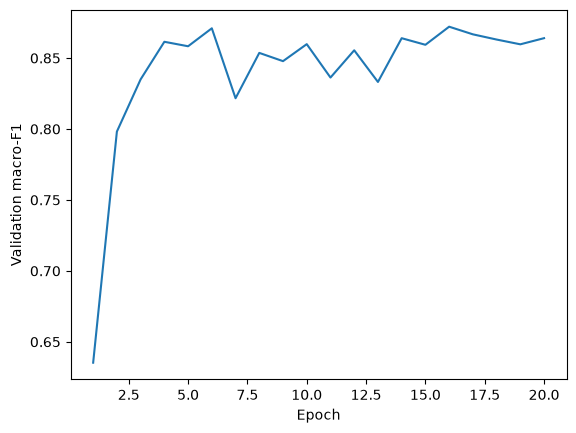

In [23]:
# 수정 금지

plt.plot([row['epoch'] for row in history], [row['val_f1'] for row in history])
plt.xlabel('Epoch')
plt.ylabel('Validation macro-F1')
plt.show()


## 최종 평가

저장된 best 모델을 validation 데이터로 평가합니다.
최하단 셀의 `[Final] Validation macro-F1`로 최종 설정의 성능을 확인하세요.
Task A의 학습 범위, Task B의 Loss 구현 조건, Task C의 수정 가능 범위를 지켜야 합니다. 성능 관련 배점 기준은 별도로 안내합니다.


In [24]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
val_loss, val_f1 = evaluate(model, val_loader, loss_fn)
print(f'[Final] Validation macro-F1: {val_f1:.4f}')


[Final] Validation macro-F1: 0.8721


## 제출

아래 파일들을 제출하세요.
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/F2_1_<수험번호>.pt`

파일명에는 첫 셀의 수험번호가 자동으로 들어갑니다. 따로 이름을 바꿀 필요가 없습니다.

- 실제로 위 결과를 만드는데 사용된 체크포인트 파일만 제출하세요.

또, 노트북에 다음 내용을 반드시 포함하세요.

- 고정한 구간과 학습한 구간, 해당 설정을 위해 수정한 코드
- 선택한 Loss와 직접 구현한 코드, 해당 Loss를 선택한 이유 (주석 작성)
- 비교한 하이퍼파라미터와 validation 결과, 최종으로 선택한 설정
- epoch별 validation macro-F1과 best validation macro-F1